In [1]:
import numpy as np
import matplotlib.pyplot as plt

from numpy.typing import NDArray
from typing import Tuple

In [2]:
# The throttle of the car should probably be proportional to its acceleration.
# We will just pick a random value here to toy around and should then later either try to optimize
# this value from some 'measurements' (using the logging print statements in makeStep) or simply
# tweak the parameters in the simulator. The former should be the useful approach in the long run
# though...

In [3]:
class PID:
    def __init__(self, pid_p: float, pid_i: float, pid_d: float, time_steps: int = 20,
                 dt: float = 0.1, desired_velocity: float = 0.5, decay_factor: float = 0):
        # Maybe re-order and re-group the parameters in here
        self.pid_p = pid_p
        self.pid_i = pid_i
        self.pid_d = pid_d

        self.time_steps = time_steps
        self.dt = dt
        self.desired_velocity = desired_velocity
        self.decay_factor = decay_factor

        self.velocity = 0
        self.throttle = 0
        self.current_time = 0

        self.have_previous_sample = False

        self.integral = 0
        self.previous_error = 0
        self.previous_time = 0

        # Lists to store simulation data for later analysis and plotting
        # Probably double-check dimensions here (because of have_previous_samples)
        self.velocities = [self.velocity]
        self.throttles = []
        self.integrals = []

    def step(self, error: float) -> float:
        if not self.have_previous_sample:
            self.previous_time = self.current_time
            self.previous_error = error
            self.have_previous_sample = True

            # Probably it would actually make most sense to return the 'integral here' (and maybe
            # just update it here and return it later)?
            return self.pid_p * error

        # Not needed with current implementation
        # dt = self.current_time - self.previous_time

        # Check for invalid (i.e. negative time deltas)
        ...

        # Valid main case update
        # First apply the decay, then add the new increment
        self.decay_integral()
        self.integral += self.dt * (error + self.previous_error) / 2
        control = self.pid_p * error + self.pid_i * self.integral + self.pid_d * (error - self.previous_error) / self.dt

        # Update previous parameters
        self.previous_time = self.current_time
        self.previous_error = error

        return control

    def decay_integral(self) -> None:
        self.integral = self.integral * (1 - self.decay_factor)

    def make_step(self) -> None:
        # 1. Compute the error
        error = self.desired_velocity - self.velocity

        # 2. Call the step function to get the throttle
        self.throttle = self.step(error)

        # 3. Add the controller quantities at the current time
        self.velocities.append(self.velocity)
        self.throttles.append(self.throttle)

        # 4. Simulate the following interval
        # 4.1. Update the remaining parameters (only velocity?)
        self.velocity += self.throttle * self.dt
        # 4.2 Increment the current time by dt
        self.current_time += self.dt
        # 4.3. Add updated velocity to the list
        self.integrals.append(self.integral)

        return None

    def run_simulation(self) -> None:
        for _ in range(self.time_steps):
            self.make_step()

        return None

    def get_data(self) -> Tuple[NDArray, NDArray, NDArray]:
        return np.array(self.velocities), np.array(self.throttles), np.array(self.integrals)

    def plot(self) -> None:
        times = np.linspace(0, self.current_time, self.time_steps + 1)

        velocity_label = f"Velocity = {self.desired_velocity:.2f}\npid_p = {self.pid_p:.3f}\npid_i = {self.pid_i:.3f}\npid_d = {self.pid_d:.3f}\ndecay_factor = {self.decay_factor:.3f}"

        plt.plot(times, self.velocities, label=velocity_label)
        plt.hlines(self.desired_velocity, 0, self.current_time, ls='--', color='black', alpha=0.5, label="Desired Velocity")

        plt.xlabel("Time in [s]")
        plt.ylabel("Velocity [m/s]")

        plt.legend(loc='lower right')
        plt.show()

        return None

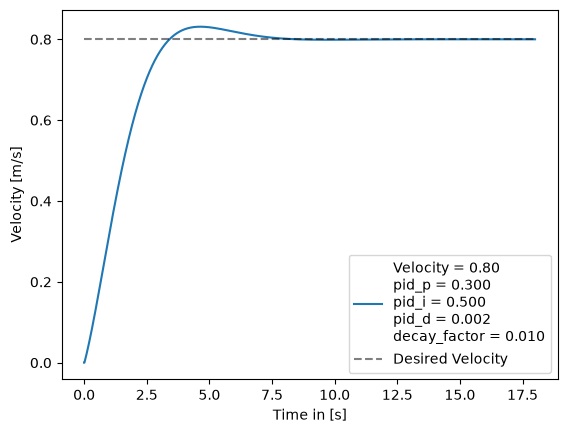

In [4]:
pid_instance = PID(pid_p=0.3, pid_i=0.5, pid_d=0.002, time_steps=1800, dt=0.01, desired_velocity=0.8, decay_factor=0.01)

pid_instance.run_simulation()

results = pid_instance.get_data()

# print(results)

pid_instance.plot()

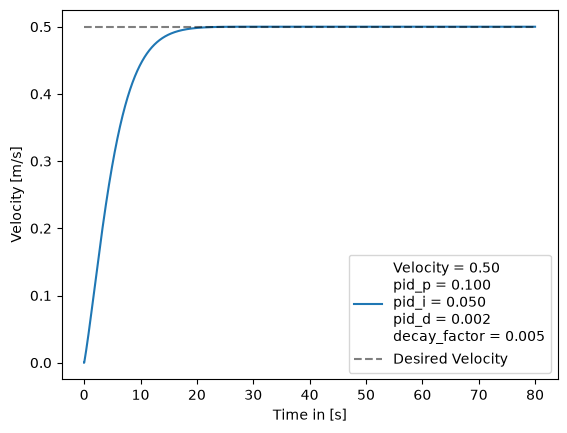

In [5]:
pid_instance_2 = PID(pid_p=0.1, pid_i=0.05, pid_d=0.002, time_steps=8000, dt=0.01, desired_velocity=0.5, decay_factor=0.005)

pid_instance_2.run_simulation()

results = pid_instance_2.get_data()

# print(results)

pid_instance_2.plot()

In [6]:
print(np.linspace(0, 10, 10))

[ 0.          1.11111111  2.22222222  3.33333333  4.44444444  5.55555556
  6.66666667  7.77777778  8.88888889 10.        ]
